# BlinkIT Grocery Sales Analysis

**Domain:** Retail & Grocery Sales Analytics
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook
**Author:** Dinesh Bhargav (AI/ML Intern, Sapphire IQ)

## Objective
Study BlinkIT's grocery sales data and tell management how products, categories, outlets and locations are performing, what drives better sales, and where performance can improve.

The notebook follows the four objectives in the project brief:
1. Understand the business and its sales performance
2. Make sure the available information is reliable (data cleaning)
3. Find out what is driving better sales performance
4. Help management make better business decisions

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="crest")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## Load the data

In [2]:
df_raw = pd.read_excel("data/BlinkIT Grocery Data.xlsx")
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (8523, 12)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.10,15.10,145.48,5.00
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.01,11.80,115.35,5.00
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.03,13.85,165.02,5.00
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.04,12.15,126.50,5.00
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.03,19.60,55.16,5.00


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   str    
 1   Item Identifier            8523 non-null   str    
 2   Item Type                  8523 non-null   str    
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   str    
 5   Outlet Location Type       8523 non-null   str    
 6   Outlet Size                8523 non-null   str    
 7   Outlet Type                8523 non-null   str    
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 799.2 KB

---
# Objective 2 — Make sure the available information is reliable
We clean the data first, so every number in Objectives 1, 3 and 4 is calculated on reliable records.

### Task 2.1 — Find missing information

In [4]:
missing = df_raw.isna().sum().to_frame("missing_count")
missing["missing_%"] = (missing["missing_count"] / len(df_raw) * 100).round(2)
missing[missing["missing_count"] > 0]

,missing_count,missing_%
Item Weight,1463,17.17


Only **Item Weight** has missing values (~17% of rows). The same item (Item Identifier) is sold in several outlets and always has the same weight, so the best fill is the weight of that same item from other rows. Any item never weighed anywhere gets the median weight of its Item Type.

In [5]:
df = df_raw.copy()
print("Distinct weights per item (max):", df.groupby("Item Identifier")["Item Weight"].nunique().max())

df["Item Weight"] = df["Item Weight"].fillna(df.groupby("Item Identifier")["Item Weight"].transform("mean"))
df["Item Weight"] = df["Item Weight"].fillna(df.groupby("Item Type")["Item Weight"].transform("median"))
print("Missing Item Weight after filling:", df["Item Weight"].isna().sum())

Distinct weights per item (max): 1
Missing Item Weight after filling: 0

### Task 2.2 — Find repeated information

In [6]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicate item-outlet pairs:", df.duplicated(["Item Identifier", "Outlet Identifier"]).sum())

Fully duplicated rows: 0
Duplicate item-outlet pairs: 0

No duplicates: every row is a unique item sold at a unique outlet.

### Task 2.3 — Find unusually high or low values

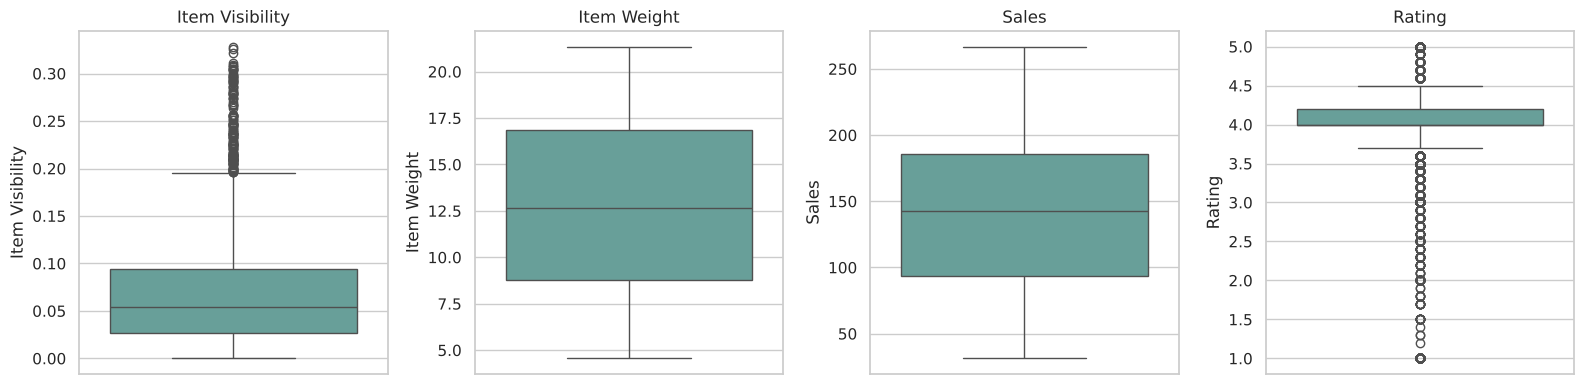

In [7]:
num_cols = ["Item Visibility", "Item Weight", "Sales", "Rating"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color="#5fa8a0")
    ax.set_title(col)
plt.tight_layout()

In [8]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

outlier_table = pd.DataFrame({
    "IQR outliers": [iqr_outliers(df[c]) for c in num_cols],
    "min": [df[c].min() for c in num_cols],
    "max": [df[c].max() for c in num_cols],
}, index=num_cols)
print("Rows with Item Visibility = 0:", (df["Item Visibility"] == 0).sum())
outlier_table

Rows with Item Visibility = 0: 526

,IQR outliers,min,max
Item Visibility,144,0.00,0.33
Item Weight,0,4.55,21.35
Sales,0,31.29,266.89
Rating,1931,1.00,5.00


Findings:
- **Sales** and **Item Weight** have no extreme outliers; their ranges are realistic.
- **Item Visibility** has some high values (legitimate: a few products get large shelf space) and **526 rows with visibility = 0**. A product on sale cannot have zero visibility, so these are recording errors. We replace them with the average visibility of the same item in other outlets.
- **Rating** has low outliers, but ratings of 1–2 are real customer feedback, so we keep them.

In [9]:
df["Item Visibility"] = df["Item Visibility"].replace(0, np.nan)
df["Item Visibility"] = df["Item Visibility"].fillna(df.groupby("Item Identifier")["Item Visibility"].transform("mean"))
df["Item Visibility"] = df["Item Visibility"].fillna(df["Item Visibility"].median())
print("Rows with zero visibility after fix:", (df["Item Visibility"] == 0).sum())

Rows with zero visibility after fix: 0

### Task 2.4 — Make similar information consistent

In [10]:
print("Before:", df["Item Fat Content"].value_counts().to_dict())
df["Item Fat Content"] = df["Item Fat Content"].replace({"LF": "Low Fat", "low fat": "Low Fat", "reg": "Regular"})
print("After: ", df["Item Fat Content"].value_counts().to_dict())

Before: {'Low Fat': 5089, 'Regular': 2889, 'LF': 316, 'reg': 117, 'low fat': 112}
After:  {'Low Fat': 5517, 'Regular': 3006}

In [11]:
# Each outlet should have exactly one size, location and type
print(df.groupby("Outlet Identifier")[["Outlet Size", "Outlet Location Type", "Outlet Type"]].nunique()
        .query("`Outlet Size` > 1 or `Outlet Location Type` > 1 or `Outlet Type` > 1"))

                   Outlet Size  Outlet Location Type  Outlet Type
Outlet Identifier                                                
OUT010                       3                     1            1
OUT017                       3                     1            1
OUT045                       3                     1            1

Outlets **OUT010, OUT017 and OUT045** are recorded with all three sizes (Small, Medium and High). One physical store can only have one size, so this is a data-entry inconsistency. We set each outlet to the size recorded most often for it.

In [12]:
size_mode = df.groupby("Outlet Identifier")["Outlet Size"].agg(lambda s: s.mode()[0])
df["Outlet Size"] = df["Outlet Identifier"].map(size_mode)
print("Corrected sizes:", size_mode[["OUT010", "OUT017", "OUT045"]].to_dict())
print("Outlets with more than one size now:", (df.groupby("Outlet Identifier")["Outlet Size"].nunique() > 1).sum())

Corrected sizes: {'OUT010': 'Medium', 'OUT017': 'Small', 'OUT045': 'Medium'}
Outlets with more than one size now: 0

In [13]:
# Trim spaces in all text columns and add helper columns
for c in df.select_dtypes(include=["object", "string"]).columns:
    df[c] = df[c].str.strip()

df["Outlet Age"] = 2026 - df["Outlet Establishment Year"]
df["Item Category"] = df["Item Identifier"].str[:2].map({"FD": "Food", "DR": "Drinks", "NC": "Non-Consumable"})
print(df.shape)
df.head()

(8523, 14)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating,Outlet Age,Item Category
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.10,15.10,145.48,5.00,14,Food
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.01,11.80,115.35,5.00,4,Non-Consumable
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.03,13.85,165.02,5.00,10,Food
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.04,12.15,126.50,5.00,12,Food
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Medium,Supermarket Type1,0.03,19.60,55.16,5.00,11,Drinks


**Cleaning summary:** missing weights filled from the same item, 526 zero visibilities fixed, fat-content labels reduced from 5 spellings to 2, inconsistent outlet sizes corrected for 3 outlets, no duplicates found. Two helper columns added: `Outlet Age` and `Item Category` (Food / Drinks / Non-Consumable, from the item-code prefix).

---
# Objective 1 — Understand the business and its sales performance

### Task 1.1 — What types of products does BlinkIT sell?

Unique products: 1559
Product types: 16
Item Category
Food              6125
Non-Consumable    1599
Drinks             799
Name: count, dtype: int64 

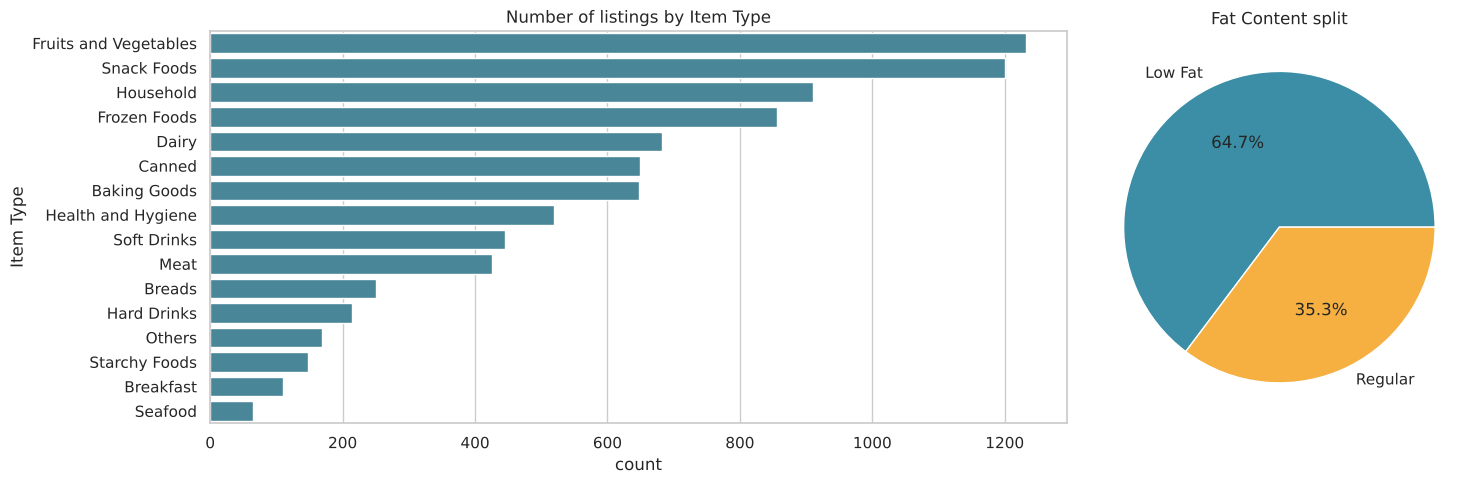

In [14]:
print("Unique products:", df["Item Identifier"].nunique())
print("Product types:", df["Item Type"].nunique())
print(df["Item Category"].value_counts(), "\n")

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2.2, 1]})
order = df["Item Type"].value_counts().index
sns.countplot(y="Item Type", data=df, order=order, ax=axes[0], color="#3b8ea5")
axes[0].set_title("Number of listings by Item Type")
df["Item Fat Content"].value_counts().plot.pie(autopct="%1.1f%%", ax=axes[1], colors=["#3b8ea5", "#f5b041"])
axes[1].set_title("Fat Content split"); axes[1].set_ylabel("")
plt.tight_layout()

BlinkIT sells **1,559 products across 16 types**. Fruits & Vegetables and Snack Foods have the widest range; about 65% of listings are Low Fat. Food items are ~72% of listings.

### Task 1.2 — Types and locations of outlets

In [15]:
outlets = (df.groupby("Outlet Identifier")
             .agg(Outlet_Type=("Outlet Type", "first"), Size=("Outlet Size", "first"),
                  Location=("Outlet Location Type", "first"), Established=("Outlet Establishment Year", "first"),
                  Products=("Item Identifier", "count"))
             .sort_values("Established"))
outlets

,Outlet_Type,Size,Location,Established,Products
Outlet Identifier,,,,,
OUT010,Grocery Store,Medium,Tier 3,2011,555
OUT049,Supermarket Type1,Medium,Tier 1,2012,930
OUT013,Supermarket Type1,High,Tier 3,2014,932
OUT045,Supermarket Type1,Medium,Tier 2,2015,929
OUT046,Supermarket Type1,Small,Tier 1,2016,930
OUT035,Supermarket Type1,Small,Tier 2,2017,930
OUT027,Supermarket Type3,Medium,Tier 3,2018,935
OUT019,Grocery Store,Small,Tier 1,2018,528
OUT017,Supermarket Type1,Small,Tier 2,2020,926


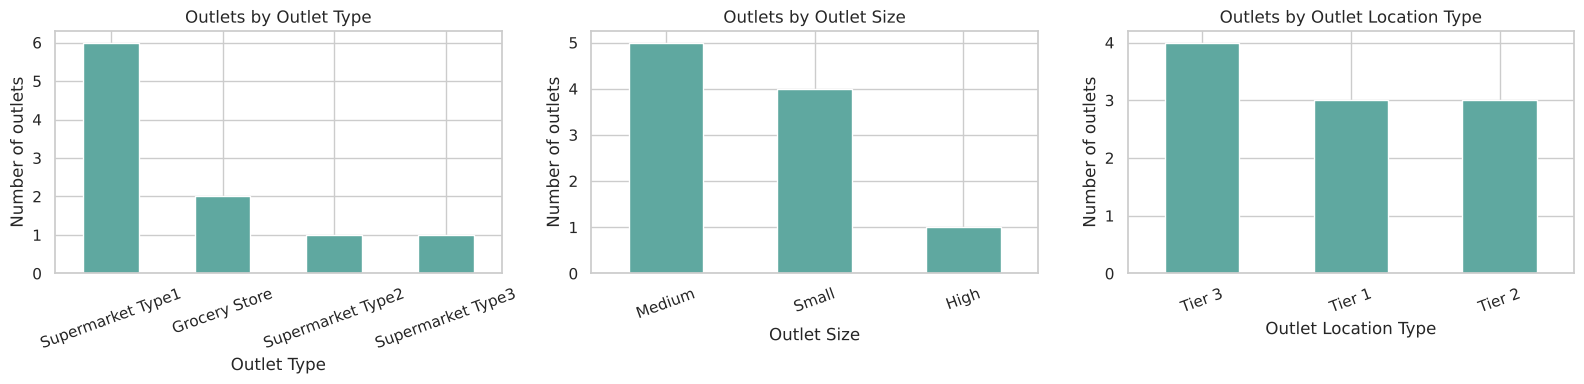

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Outlet Type", "Outlet Size", "Outlet Location Type"]):
    outlets_col = df.drop_duplicates("Outlet Identifier")[col].value_counts()
    outlets_col.plot.bar(ax=ax, color="#5fa8a0")
    ax.set_title(f"Outlets by {col}"); ax.set_ylabel("Number of outlets"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout()

There are **10 outlets**: 6 Supermarket Type1, 2 Grocery Stores, 1 Supermarket Type2 and 1 Type3, spread across Tier 1, 2 and 3 cities and opened between 2011 and 2022.

### Task 1.3 — How much is BlinkIT selling overall?

In [17]:
total_sales = df["Sales"].sum()
kpis = pd.Series({
    "Total Sales": total_sales,
    "Average Sales per item listing": df["Sales"].mean(),
    "Number of items sold (listings)": len(df),
    "Average Rating": df["Rating"].mean(),
})
print(kpis.apply(lambda v: f"{v:,.2f}"))

Total Sales                        1,201,681.49
Average Sales per item listing           140.99
Number of items sold (listings)        8,523.00
Average Rating                             3.97
dtype: str

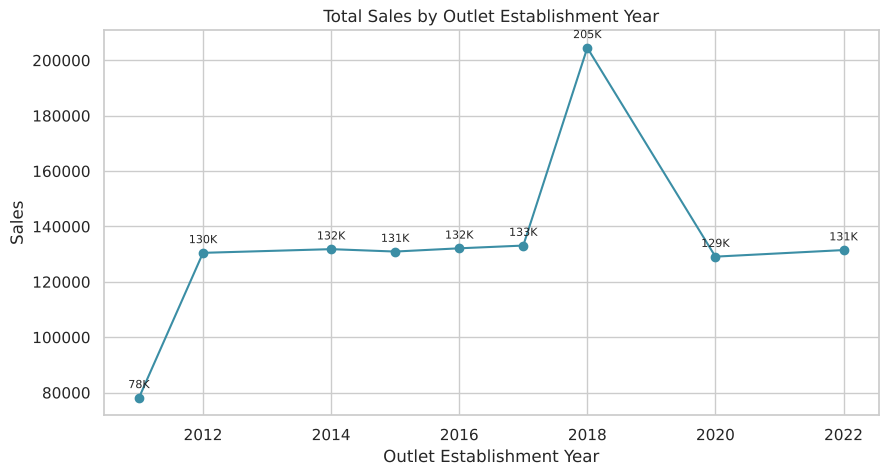

In [18]:
yearly = df.groupby("Outlet Establishment Year")["Sales"].sum()
ax = yearly.plot(marker="o", color="#3b8ea5")
ax.set_title("Total Sales by Outlet Establishment Year"); ax.set_ylabel("Sales")
for x, y in yearly.items():
    ax.annotate(f"{y/1000:,.0f}K", (x, y), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)

Total sales are about **1.20 million** across 8,523 item listings, with an average of ~141 per listing. Outlets opened in 2018 contribute the most sales (~205K) only because two outlets (OUT019 and OUT027) opened that year. Every other year has one outlet with ~130K, except 2011 (OUT010, a grocery store, ~78K).

### Task 1.4 — Overall customer rating and product performance

Ratings >= 4: 76.4%

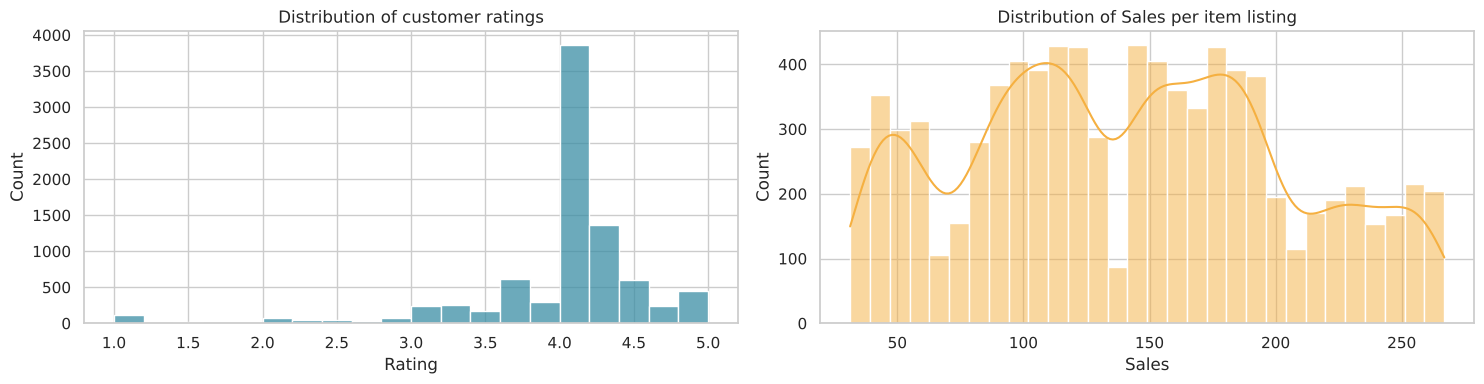

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(df["Rating"], bins=20, ax=axes[0], color="#3b8ea5")
axes[0].set_title("Distribution of customer ratings")
sns.histplot(df["Sales"], bins=30, kde=True, ax=axes[1], color="#f5b041")
axes[1].set_title("Distribution of Sales per item listing")
plt.tight_layout()
print("Ratings >= 4:", f"{(df['Rating'] >= 4).mean():.1%}")

Customers are generally satisfied: the average rating is **3.97** and about 76% of listings are rated 4.0 or above. Sales per listing range from about 31 to 267 with no extreme spikes.

---
# Objective 3 — What is driving better sales performance?

### Task 3.1 — Which product types sell more?

In [20]:
by_type = (df.groupby("Item Type")["Sales"]
              .agg(Total="sum", Average="mean", Listings="count")
              .sort_values("Total", ascending=False))
by_type["Share_%"] = by_type["Total"] / total_sales * 100
by_type

,Total,Average,Listings,Share_%
Item Type,,,,
Fruits and Vegetables,"178,124.08",144.58,1232,14.82
Snack Foods,"175,433.92",146.19,1200,14.60
Household,"135,976.53",149.42,910,11.32
Frozen Foods,"118,558.88",138.50,856,9.87
Dairy,"101,276.46",148.50,682,8.43
Canned,"90,706.73",139.76,649,7.55
Baking Goods,"81,894.74",126.38,648,6.82
Health and Hygiene,"68,025.84",130.82,520,5.66
Meat,"59,449.86",139.88,425,4.95


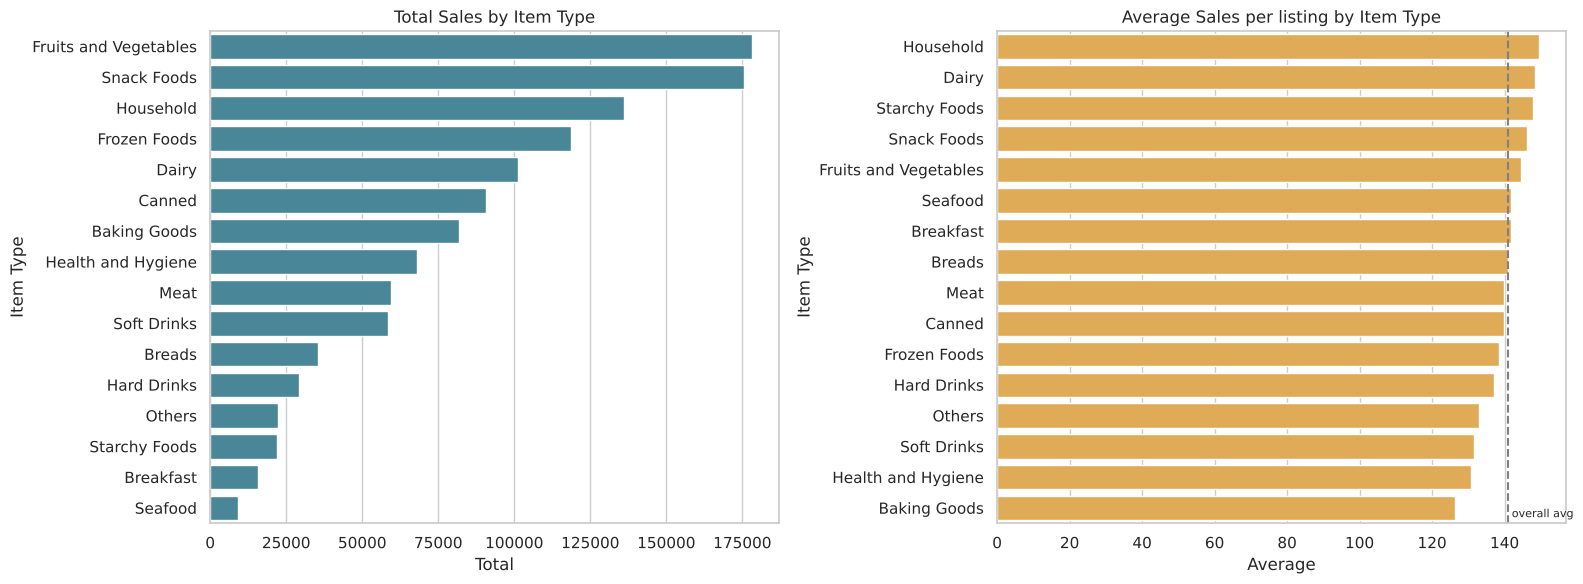

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(x=by_type["Total"], y=by_type.index, ax=axes[0], color="#3b8ea5")
axes[0].set_title("Total Sales by Item Type")
avg = by_type.sort_values("Average", ascending=False)
sns.barplot(x=avg["Average"], y=avg.index, ax=axes[1], color="#f5b041")
axes[1].set_title("Average Sales per listing by Item Type")
axes[1].axvline(df["Sales"].mean(), ls="--", c="grey"); axes[1].text(df["Sales"].mean() + 1, 15.3, "overall avg", fontsize=8)
plt.tight_layout()

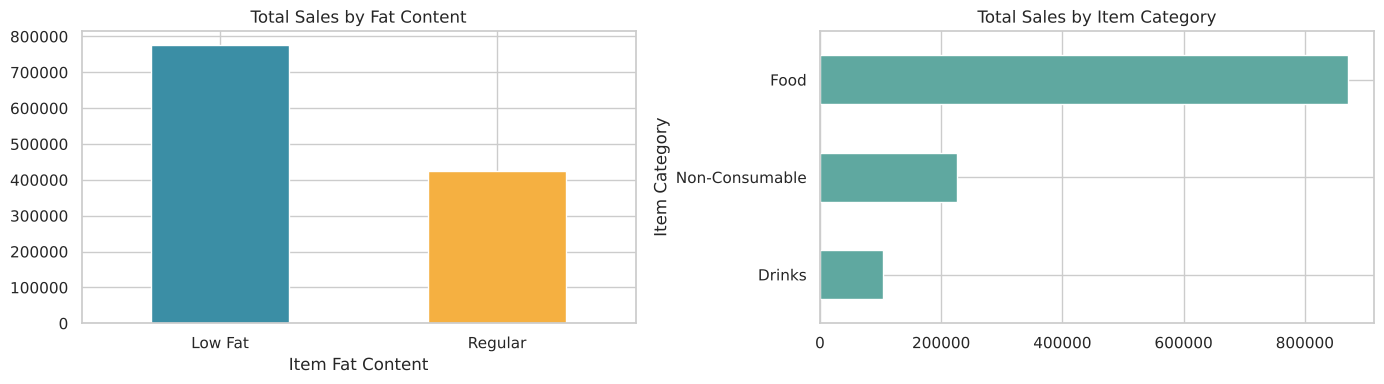

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df.groupby("Item Fat Content")["Sales"].sum().plot.bar(ax=axes[0], color=["#3b8ea5", "#f5b041"])
axes[0].set_title("Total Sales by Fat Content"); axes[0].tick_params(axis="x", rotation=0)
df.groupby("Item Category")["Sales"].sum().sort_values().plot.barh(ax=axes[1], color="#5fa8a0")
axes[1].set_title("Total Sales by Item Category")
plt.tight_layout()

**Fruits & Vegetables** and **Snack Foods** bring in the most total sales (~15% and ~14%), mainly because they have the most listings. Per listing, **Household, Dairy, Starchy Foods and Snack Foods** sell slightly above average (146–149 vs 141), while Baking Goods and Health & Hygiene sell below average. Average sales are similar across product types, so how many listings a category has matters more than which category it is.

### Task 3.2 — Which outlets perform better?

In [23]:
by_outlet_type = (df.groupby("Outlet Type")
                    .agg(Total_Sales=("Sales", "sum"), Avg_Sales=("Sales", "mean"),
                         Listings=("Sales", "count"), Outlets=("Outlet Identifier", "nunique"),
                         Avg_Rating=("Rating", "mean"))
                    .sort_values("Total_Sales", ascending=False))
by_outlet_type["Sales_per_Outlet"] = by_outlet_type["Total_Sales"] / by_outlet_type["Outlets"]
by_outlet_type

,Total_Sales,Avg_Sales,Listings,Outlets,Avg_Rating,Sales_per_Outlet
Outlet Type,,,,,,
Supermarket Type1,"787,549.89",141.21,5577,6,3.96,"131,258.32"
Grocery Store,"151,939.15",140.29,1083,2,3.99,"75,969.57"
Supermarket Type2,"131,477.78",141.68,928,1,3.97,"131,477.78"
Supermarket Type3,"130,714.67",139.80,935,1,3.95,"130,714.67"


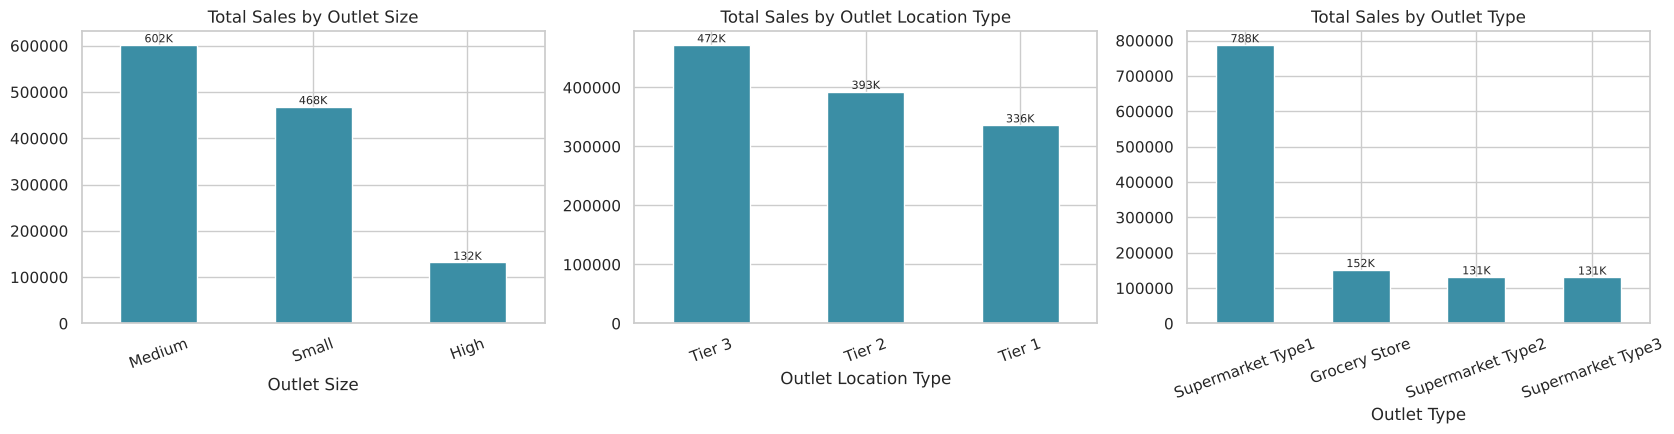

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ["Outlet Size", "Outlet Location Type", "Outlet Type"]):
    s = df.groupby(col)["Sales"].sum().sort_values(ascending=False)
    s.plot.bar(ax=ax, color="#3b8ea5")
    ax.set_title(f"Total Sales by {col}"); ax.tick_params(axis="x", rotation=20)
    for i, v in enumerate(s):
        ax.text(i, v, f"{v/1000:,.0f}K", ha="center", va="bottom", fontsize=8)
plt.tight_layout()

In [25]:
by_outlet = (df.groupby(["Outlet Identifier", "Outlet Type", "Outlet Location Type", "Outlet Size"])["Sales"]
               .agg(Total="sum", Average="mean", Listings="count")
               .sort_values("Total", ascending=False).reset_index())
by_outlet

,Outlet Identifier,Outlet Type,Outlet Location Type,Outlet Size,Total,Average,Listings
0,OUT035,Supermarket Type1,Tier 2,Small,"133,103.91",143.12,930
1,OUT046,Supermarket Type1,Tier 1,Small,"132,113.37",142.06,930
2,OUT013,Supermarket Type1,Tier 3,High,"131,809.02",141.43,932
3,OUT018,Supermarket Type2,Tier 3,Medium,"131,477.78",141.68,928
4,OUT045,Supermarket Type1,Tier 2,Medium,"130,942.78",140.95,929
5,OUT027,Supermarket Type3,Tier 3,Medium,"130,714.67",139.80,935
6,OUT049,Supermarket Type1,Tier 1,Medium,"130,476.86",140.30,930
7,OUT017,Supermarket Type1,Tier 2,Small,"129,103.96",139.42,926
8,OUT010,Grocery Store,Tier 3,Medium,"78,131.57",140.78,555
9,OUT019,Grocery Store,Tier 1,Small,"73,807.58",139.79,528


**Supermarket Type1** outlets bring in about **65% of total sales**, because there are six of them. Per outlet, though, all four supermarket types sell about the same (~131K each). The **2 Grocery Stores sell only ~76K each, about 58% of a supermarket**. They carry far fewer products (~540 listings vs ~930), while sales per listing are about the same (~140). **Tier 3** cities lead total sales because they have the most outlets (4).

### Task 3.3 — Are visibility, weight, ratings and outlet characteristics connected with sales?

Text(0.5, 1.0, 'Correlation between numeric features and Sales')

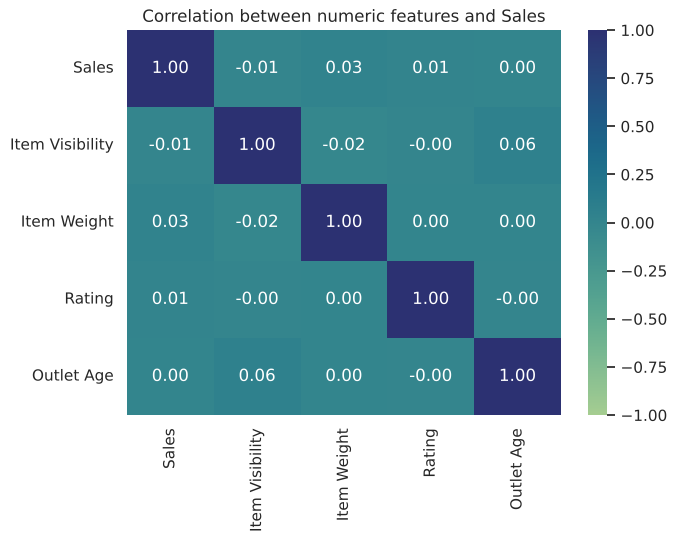

In [26]:
corr_cols = ["Sales", "Item Visibility", "Item Weight", "Rating", "Outlet Age"]
plt.figure(figsize=(7, 5))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="crest", vmin=-1, vmax=1)
plt.title("Correlation between numeric features and Sales")

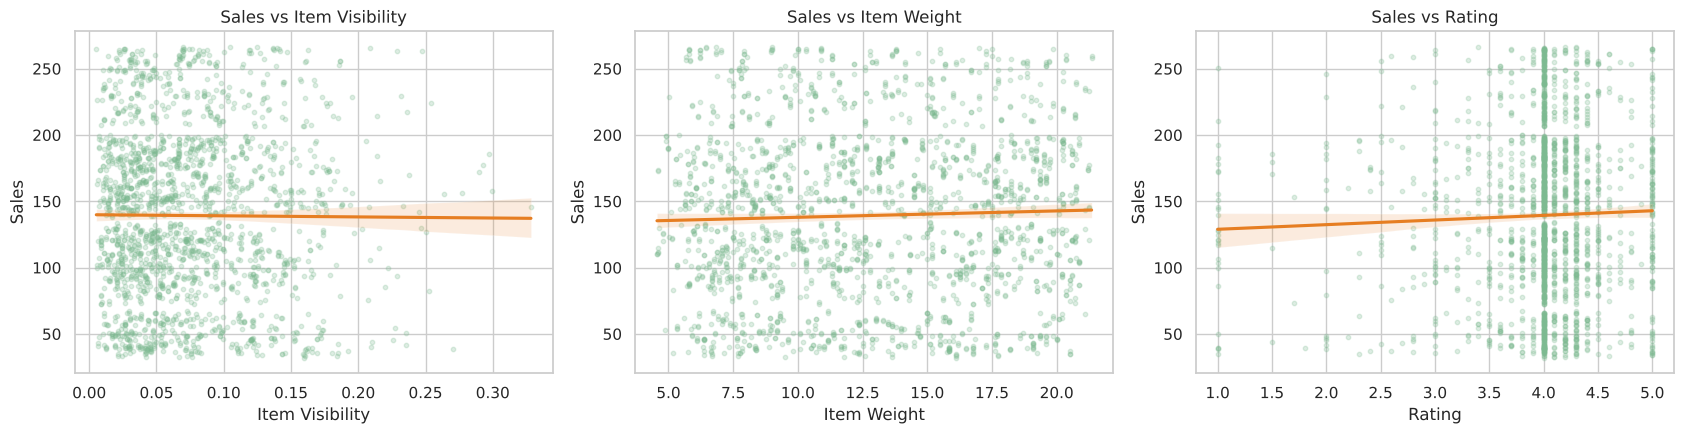

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ["Item Visibility", "Item Weight", "Rating"]):
    sns.regplot(x=col, y="Sales", data=df.sample(2000, random_state=42), ax=ax,
                scatter_kws={"alpha": 0.25, "s": 10}, line_kws={"color": "#e67e22"})
    ax.set_title(f"Sales vs {col}")
plt.tight_layout()

In [28]:
# Average sales across outlet characteristics
for col in ["Outlet Type", "Outlet Size", "Outlet Location Type"]:
    print(df.groupby(col)["Sales"].mean().round(2).to_dict())

{'Grocery Store': 140.29, 'Supermarket Type1': 141.21, 'Supermarket Type2': 141.68, 'Supermarket Type3': 139.8}
{'High': 141.43, 'Medium': 140.69, 'Small': 141.26}
{'Tier 1': 140.87, 'Tier 2': 141.17, 'Tier 3': 140.94}

Visibility, weight, rating and outlet age have **almost no linear relationship** with sales per listing (all correlations are close to 0). Outlet characteristics also barely change sales per listing. The real driver is **how many products an outlet stocks**: supermarkets carry ~1.7× as many products as grocery stores, and their sales per outlet are ~1.7× higher, in exactly the same proportion.

### Task 3.4 — Compare better- and lower-performing products and outlets

In [29]:
prod = df.groupby(["Item Identifier", "Item Type"])["Sales"].sum().reset_index()
prod["Tier"] = pd.qcut(prod["Sales"], 4, labels=["Bottom 25%", "Q2", "Q3", "Top 25%"])
prod_feat = df.groupby("Item Identifier").agg(Visibility=("Item Visibility", "mean"),
                                              Weight=("Item Weight", "first"),
                                              Rating=("Rating", "mean"),
                                              Outlets=("Outlet Identifier", "nunique"))
prod = prod.merge(prod_feat, on="Item Identifier")
compare = prod[prod["Tier"].isin(["Top 25%", "Bottom 25%"])].groupby("Tier", observed=True)[
    ["Sales", "Outlets", "Visibility", "Weight", "Rating"]].mean()
compare

,Sales,Outlets,Visibility,Weight,Rating
Tier,,,,,
Bottom 25%,296.50,4.66,0.07,12.33,3.96
Top 25%,"1,344.45",6.57,0.07,13.07,3.96


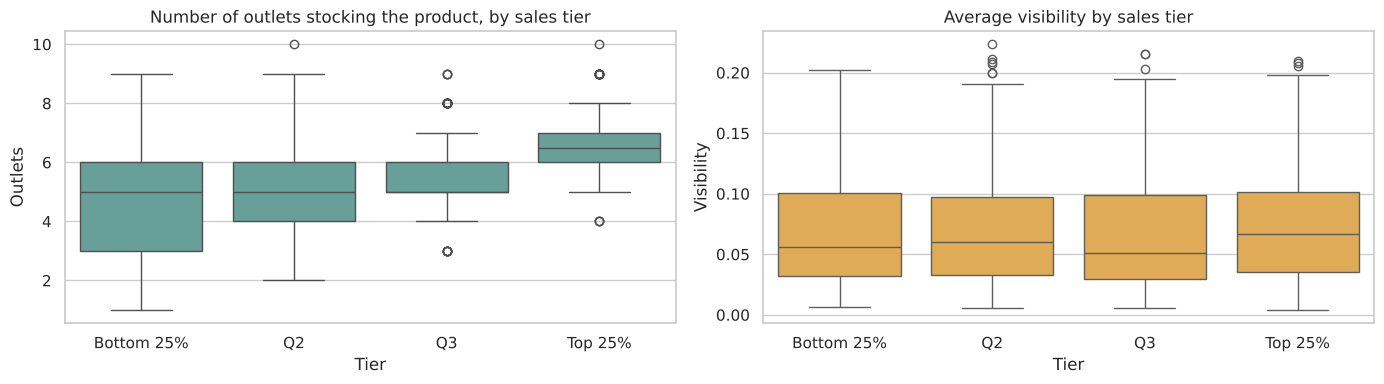

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x="Tier", y="Outlets", data=prod, ax=axes[0], color="#5fa8a0")
axes[0].set_title("Number of outlets stocking the product, by sales tier")
sns.boxplot(x="Tier", y="Visibility", data=prod, ax=axes[1], color="#f5b041")
axes[1].set_title("Average visibility by sales tier")
plt.tight_layout()

Top-25% products are stocked in **about 6.6 outlets on average vs about 4.7** for bottom-25% products. Their visibility, weight and rating are almost the same. A product sells more mainly because it is **available in more outlets**, not because of its shelf visibility or rating.

---
# Objective 4 — Help management make better business decisions

### Task 4.1 — Products contributing most to sales

In [31]:
top_products = (df.groupby(["Item Identifier", "Item Type"])["Sales"].sum()
                  .sort_values(ascending=False).head(10).reset_index())
top_products["Share_%"] = top_products["Sales"] / total_sales * 100
top_products

,Item Identifier,Item Type,Sales,Share_%
0,FDU12,Baking Goods,"2,371.01",0.20
1,FDT07,Fruits and Vegetables,"2,306.90",0.19
2,NCQ06,Household,"2,294.71",0.19
3,FDL58,Snack Foods,"2,111.65",0.18
4,NCB31,Household,"2,104.73",0.18
5,FDX31,Fruits and Vegetables,"2,104.46",0.18
6,FDF05,Frozen Foods,"2,103.13",0.18
7,FDR59,Breads,"2,096.58",0.17
8,FDP28,Frozen Foods,"2,087.85",0.17
9,FDA04,Frozen Foods,"2,072.07",0.17


931 of 1559 products (60%) generate 80% of sales

Text(0, 0.5, 'Cumulative % of sales')

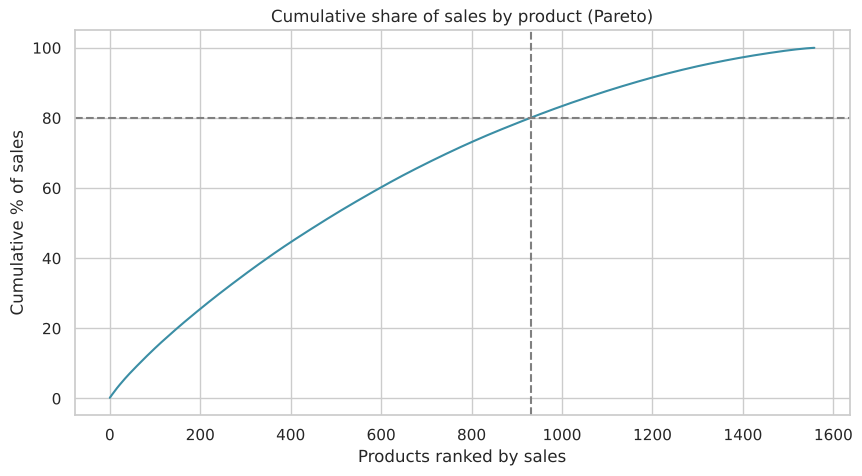

In [32]:
pareto = df.groupby("Item Identifier")["Sales"].sum().sort_values(ascending=False)
cum = pareto.cumsum() / pareto.sum() * 100
n80 = (cum <= 80).sum() + 1
print(f"{n80} of {len(pareto)} products ({n80/len(pareto):.0%}) generate 80% of sales")
ax = cum.reset_index(drop=True).plot(color="#3b8ea5")
ax.axhline(80, ls="--", c="grey"); ax.axvline(n80, ls="--", c="grey")
ax.set_title("Cumulative share of sales by product (Pareto)"); ax.set_xlabel("Products ranked by sales"); ax.set_ylabel("Cumulative % of sales")

### Task 4.2 — Outlets and locations that perform better

Text(0.5, 1.0, 'Total Sales (K) by Location Tier and Outlet Type')

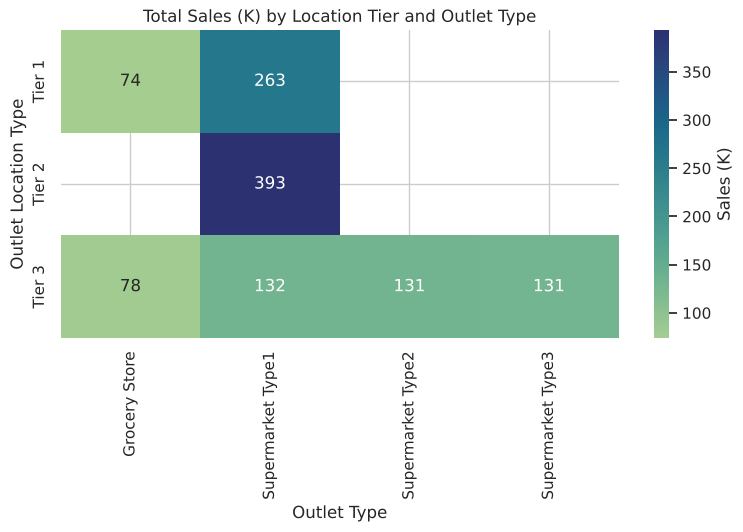

In [33]:
pivot = df.pivot_table(index="Outlet Location Type", columns="Outlet Type", values="Sales", aggfunc="sum")
plt.figure(figsize=(9, 4))
sns.heatmap(pivot / 1000, annot=True, fmt=".0f", cmap="crest", cbar_kws={"label": "Sales (K)"})
plt.title("Total Sales (K) by Location Tier and Outlet Type")

In [34]:
loc = df.groupby("Outlet Location Type").agg(Total=("Sales", "sum"), Outlets=("Outlet Identifier", "nunique"))
loc["Sales_per_Outlet"] = loc["Total"] / loc["Outlets"]
loc

,Total,Outlets,Sales_per_Outlet
Outlet Location Type,,,
Tier 1,"336,397.81",3,"112,132.60"
Tier 2,"393,150.65",3,"131,050.22"
Tier 3,"472,133.03",4,"118,033.26"


The best performers are the eight supermarkets, each selling ~129–134K; OUT035 and OUT046 top the list. Tier 3 has the highest total sales because it has the most outlets (4), including the only Type2 and Type3 supermarkets. Tier 2 has the best average sales per outlet because all three of its outlets are supermarkets.

### Task 4.3 — Where performance can improve

In [35]:
weak_outlets = by_outlet.sort_values("Total").head(3)
print("Lowest-selling outlets:")
print(weak_outlets.to_string(index=False), "\n")

weak_types = by_type.sort_values("Total").head(5)[["Total", "Average", "Listings", "Share_%"]]
print("Lowest-selling product types:")
print(weak_types.round(2).to_string(), "\n")

low_rated = df.groupby("Item Type")["Rating"].mean().sort_values().head(3)
print("Lowest average rating by type:", low_rated.round(2).to_dict())

Lowest-selling outlets:
Outlet Identifier       Outlet Type Outlet Location Type Outlet Size      Total  Average  Listings
           OUT019     Grocery Store               Tier 1       Small  73,807.58   139.79       528
           OUT010     Grocery Store               Tier 3      Medium  78,131.57   140.78       555
           OUT017 Supermarket Type1               Tier 2       Small 129,103.96   139.42       926 

Lowest-selling product types:
                  Total  Average  Listings  Share_%
Item Type                                          
Seafood        9,077.87   141.84        64     0.76
Breakfast     15,596.70   141.79       110     1.30
Starchy Foods 21,880.03   147.84       148     1.82
Others        22,451.89   132.85       169     1.87
Hard Drinks   29,334.68   137.08       214     2.44 

Lowest average rating by type: {'Breads': 3.88, 'Hard Drinks': 3.91, 'Starchy Foods': 3.92}

- **Grocery Stores (OUT010, OUT019)** sell only ~58% as much as a supermarket because their product range is much smaller.
- **Seafood, Breakfast, Starchy Foods, Others and Hard Drinks** each bring in under 2.5% of sales because they have few listings. Starchy Foods actually sells above average per listing.
- **Breads, Hard Drinks and Starchy Foods** have the lowest average ratings (3.88–3.92), which is worth checking for quality or freshness issues.
- **Bottom-quartile products** are stocked in fewer outlets (~4.7 vs ~6.6), so there is room to grow by stocking them more widely.

### Task 4.4 — Practical suggestions

1. **Widen the range in Grocery Stores.** Sales per listing there are about the same as in supermarkets, so the gap comes almost entirely from the smaller range. Adding the top-selling products (Fruits & Vegetables, Snack Foods, Household, Dairy) should raise their sales.
2. **Stock good products in more outlets.** Top products sell more mainly because they are in more stores. Roll out bottom-quartile products that have good ratings to more outlets before dropping them.
3. **Grow categories that sell well per listing.** Starchy Foods sells above average per listing but has very few products, so add more SKUs there. Household and Dairy also sell above average and deserve more shelf range.
4. **Focus inventory on the ~60% of products that make 80% of sales.** Keep these always in stock, and review the slow-moving tail for removal.
5. **Prefer the supermarket format for new outlets.** Every supermarket sells ~130K regardless of city tier, and Tier 2 (all supermarkets) has the best sales per outlet.
6. **Fix data capture.** Item weight was missing for 17% of records, visibility was recorded as 0 for 526 items, and three outlets had conflicting sizes. Make these fields mandatory in the billing and inventory system.
7. **Don't rely on shelf visibility or ratings alone to boost sales.** Neither showed a real link to sales. Spend promotion money on availability and range instead.

---
## Conclusion
BlinkIT's sales of ~1.20M come mostly from Supermarket Type1 outlets and from Fruits & Vegetables and Snack Foods. The analysis shows that **product range and availability across outlets**, not visibility, weight or rating, drive sales. The biggest opportunities are widening the range in grocery stores, stocking proven products in more outlets, and adding more products to categories that sell well per listing.

In [36]:
df.to_csv("data/blinkit_cleaned.csv", index=False)
print("Cleaned data saved:", df.shape)

Cleaned data saved: (8523, 14)